<a href="https://colab.research.google.com/github/Group-9-AI-ML-class-A/Diabetes-Risk-screener/blob/main/Group_9_high_recall_diabetic_risk_screener.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

In [2]:
#This line will read/capture the data from it source
df=pd.read_csv("diabetic risk data for grp 9.csv")

In [3]:
#To view the number of rows and columns
df.shape

(15000, 19)

In [4]:
df.head()  #To dis[lay the first five rows]

,patient_id,age,gender,city,bmi,family_history_diabetes,physical_activity_level,diet_type,smoking_status,alcohol_consumption,hours_sleep_per_night,stress_level,fasting_blood_sugar,hba1c_level,blood_pressure_systolic,blood_pressure_diastolic,waist_circumference_cm,income_bracket,diabetes_risk
0,1,47,Female,Mumbai,26.5,Yes,Sedentary,Vegetarian,Never,Never,9.0,8,178,7.3,146,90,107.1,High,Low
1,2,53,Female,Mumbai,20.5,Yes,Moderate,Vegetarian,Never,Never,7.0,6,152,6.9,156,100,93.8,Low,Low
2,3,47,Male,Thane,31.3,No,Moderate,Non-Vegetarian,Current,Regular,7.0,7,168,6.6,150,102,113.5,Low,High
3,4,41,Male,Bengaluru,22.8,No,Sedentary,Non-Vegetarian,Never,Never,9.0,5,155,6.7,126,92,109.6,Middle,Low
4,5,57,Female,Bengaluru,16.7,No,Sedentary,Non-Vegetarian,Current,Occasional,6.5,10,188,6.7,130,90,80.8,High,Low


In [5]:
df.tail() #To dis[lay the last five rows]

,patient_id,age,gender,city,bmi,family_history_diabetes,physical_activity_level,diet_type,smoking_status,alcohol_consumption,hours_sleep_per_night,stress_level,fasting_blood_sugar,hba1c_level,blood_pressure_systolic,blood_pressure_diastolic,waist_circumference_cm,income_bracket,diabetes_risk
14995,14996,47,Male,Mumbai,37.7,No,Sedentary,Non-Vegetarian,Never,Never,6.8,7,213,8.1,150,100,141.7,High,High
14996,14997,48,Female,Mumbai,20.6,No,Moderate,Non-Vegetarian,Never,NaN,6.0,8,162,6.5,132,80,91.0,NaN,Low
14997,14998,34,Female,Nagpur,17.9,No,Active,Vegetarian,Never,Never,7.0,6,137,6.5,136,90,88.8,Low,Low
14998,14999,56,Male,Ahmedabad,20.7,Yes,Active,Vegetarian,Never,Never,6.0,5,163,6.9,140,87,94.8,Low,Low
14999,15000,54,Male,Surat,34.5,No,Moderate,Vegetarian,Never,Never,7.4,2,186,7.2,150,88,130.4,Middle,Moderate


In [6]:
#To give information about the Data in  the Dataframe
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 19 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   patient_id                15000 non-null  int64  
 1   age                       15000 non-null  int64  
 2   gender                    15000 non-null  object 
 3   city                      15000 non-null  object 
 4   bmi                       15000 non-null  float64
 5   family_history_diabetes   15000 non-null  object 
 6   physical_activity_level   15000 non-null  object 
 7   diet_type                 15000 non-null  object 
 8   smoking_status            14528 non-null  object 
 9   alcohol_consumption       11212 non-null  object 
 10  hours_sleep_per_night     15000 non-null  float64
 11  stress_level              15000 non-null  int64  
 12  fasting_blood_sugar       15000 non-null  int64  
 13  hba1c_level               15000 non-null  float64
 14  blood_

In [7]:
#To give comprehensive details about the column statistical information
df.describe()

,patient_id,age,bmi,hours_sleep_per_night,stress_level,fasting_blood_sugar,hba1c_level,blood_pressure_systolic,blood_pressure_diastolic,waist_circumference_cm
count,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,7500.500000,44.333667,23.062260,7.309860,5.941200,168.789933,6.878387,139.496200,86.256933,100.207933
std,4330.271354,10.383753,4.046391,1.109372,2.148406,38.365822,0.843276,12.660785,8.386529,10.760331
min,1.000000,18.000000,15.000000,3.000000,1.000000,72.000000,4.800000,80.000000,50.000000,73.200000
25%,3750.750000,38.000000,20.100000,6.700000,4.000000,145.000000,6.300000,130.000000,80.000000,92.500000
50%,7500.500000,45.000000,22.700000,7.000000,6.000000,165.000000,6.800000,140.000000,88.000000,99.300000
75%,11250.250000,52.000000,25.600000,8.000000,7.000000,189.000000,7.300000,150.000000,90.000000,106.900000
max,15000.000000,80.000000,40.800000,12.000000,10.000000,400.000000,13.400000,200.000000,120.000000,148.200000


In [8]:
#To check for missing value within the Dataframe
df.isnull().sum()

,0
patient_id,0
age,0
gender,0
city,0
bmi,0
family_history_diabetes,0
physical_activity_level,0
diet_type,0
smoking_status,472
alcohol_consumption,3788


In [9]:
#false shows there is no missing value while True confirm cells will missing values
df.isnull()

,patient_id,age,gender,city,bmi,family_history_diabetes,physical_activity_level,diet_type,smoking_status,alcohol_consumption,hours_sleep_per_night,stress_level,fasting_blood_sugar,hba1c_level,blood_pressure_systolic,blood_pressure_diastolic,waist_circumference_cm,income_bracket,diabetes_risk
0,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14995,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
14996,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,True,False
14997,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
14998,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False


In [10]:
#To check for duplicates
df.duplicated().sum()

np.int64(0)

In [11]:
#for Non-numerical value, Mode is used to fill the missing data
df['smoking_status'] = df['smoking_status'].fillna(df['smoking_status'].mode()[0])

In [12]:
df.isnull().sum() #To further check for missing value within the Dataframe

,0
patient_id,0
age,0
gender,0
city,0
bmi,0
family_history_diabetes,0
physical_activity_level,0
diet_type,0
smoking_status,0
alcohol_consumption,3788


In [13]:
#Unknown is used to fill the missing data
df['alcohol_consumption'] = df['alcohol_consumption'].fillna('Unknown')

In [14]:
df.isnull().sum() #To confirm the missing column features fix

,0
patient_id,0
age,0
gender,0
city,0
bmi,0
family_history_diabetes,0
physical_activity_level,0
diet_type,0
smoking_status,0
alcohol_consumption,0


In [15]:
 #To confirm the first and last five(5) rows again
df

,patient_id,age,gender,city,bmi,family_history_diabetes,physical_activity_level,diet_type,smoking_status,alcohol_consumption,hours_sleep_per_night,stress_level,fasting_blood_sugar,hba1c_level,blood_pressure_systolic,blood_pressure_diastolic,waist_circumference_cm,income_bracket,diabetes_risk
0,1,47,Female,Mumbai,26.5,Yes,Sedentary,Vegetarian,Never,Never,9.0,8,178,7.3,146,90,107.1,High,Low
1,2,53,Female,Mumbai,20.5,Yes,Moderate,Vegetarian,Never,Never,7.0,6,152,6.9,156,100,93.8,Low,Low
2,3,47,Male,Thane,31.3,No,Moderate,Non-Vegetarian,Current,Regular,7.0,7,168,6.6,150,102,113.5,Low,High
3,4,41,Male,Bengaluru,22.8,No,Sedentary,Non-Vegetarian,Never,Never,9.0,5,155,6.7,126,92,109.6,Middle,Low
4,5,57,Female,Bengaluru,16.7,No,Sedentary,Non-Vegetarian,Current,Occasional,6.5,10,188,6.7,130,90,80.8,High,Low
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14995,14996,47,Male,Mumbai,37.7,No,Sedentary,Non-Vegetarian,Never,Never,6.8,7,213,8.1,150,100,141.7,High,High
14996,14997,48,Female,Mumbai,20.6,No,Moderate,Non-Vegetarian,Never,Unknown,6.0,8,162,6.5,132,80,91.0,NaN,Low
14997,14998,34,Female,Nagpur,17.9,No,Active,Vegetarian,Never,Never,7.0,6,137,6.5,136,90,88.8,Low,Low
14998,14999,56,Male,Ahmedabad,20.7,Yes,Active,Vegetarian,Never,Never,6.0,5,163,6.9,140,87,94.8,Low,Low


In [16]:
df['diabetes_risk'] = df['diabetes_risk'].map({
    'Low': 'Low',
    'Moderate': 'At_Risk',
    'High': 'At_Risk'
})

In [17]:
#drop columns that won't be necessry to train the model
df = df.drop(columns=['patient_id', 'city', 'income_bracket'], errors='ignore')
X = df.drop(columns=['diabetes_risk'], errors='ignore')
#drop disbetes risk in X and assign it to Y
y = df['diabetes_risk']
print(X.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 15 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   age                       15000 non-null  int64  
 1   gender                    15000 non-null  object 
 2   bmi                       15000 non-null  float64
 3   family_history_diabetes   15000 non-null  object 
 4   physical_activity_level   15000 non-null  object 
 5   diet_type                 15000 non-null  object 
 6   smoking_status            15000 non-null  object 
 7   alcohol_consumption       15000 non-null  object 
 8   hours_sleep_per_night     15000 non-null  float64
 9   stress_level              15000 non-null  int64  
 10  fasting_blood_sugar       15000 non-null  int64  
 11  hba1c_level               15000 non-null  float64
 12  blood_pressure_systolic   15000 non-null  int64  
 13  blood_pressure_diastolic  15000 non-null  int64  
 14  waist_

In [18]:
pd.crosstab(pd.cut(df['hba1c_level'], [0, 5.7, 6.5, 20]), df['diabetes_risk'])

diabetes_risk,At_Risk,Low
hba1c_level,,
"(0.0, 5.7]",0,1067
"(5.7, 6.5]",303,4106
"(6.5, 20.0]",5697,3827


In [19]:
df = df.drop(columns=['fasting_blood_sugar', 'hba1c_level'], errors='ignore')
X = df.drop(columns=['diabetes_risk'], errors='ignore')

In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 14 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   age                       15000 non-null  int64  
 1   gender                    15000 non-null  object 
 2   bmi                       15000 non-null  float64
 3   family_history_diabetes   15000 non-null  object 
 4   physical_activity_level   15000 non-null  object 
 5   diet_type                 15000 non-null  object 
 6   smoking_status            15000 non-null  object 
 7   alcohol_consumption       15000 non-null  object 
 8   hours_sleep_per_night     15000 non-null  float64
 9   stress_level              15000 non-null  int64  
 10  blood_pressure_systolic   15000 non-null  int64  
 11  blood_pressure_diastolic  15000 non-null  int64  
 12  waist_circumference_cm    15000 non-null  float64
 13  diabetes_risk             15000 non-null  object 
dtypes: flo

In [21]:
#
X_encoded = pd.get_dummies(X, drop_first=True)
print(X_encoded.head())


   age   bmi  hours_sleep_per_night  stress_level  blood_pressure_systolic  \
0   47  26.5                    9.0             8                      146   
1   53  20.5                    7.0             6                      156   
2   47  31.3                    7.0             7                      150   
3   41  22.8                    9.0             5                      126   
4   57  16.7                    6.5            10                      130   

   blood_pressure_diastolic  waist_circumference_cm  gender_Male  \
0                        90                   107.1        False   
1                       100                    93.8        False   
2                       102                   113.5         True   
3                        92                   109.6         True   
4                        90                    80.8        False   

   gender_Other  family_history_diabetes_Yes  \
0         False                         True   
1         False           

In [22]:
X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print(f"Training data shape: {X_train_scaled.shape}")
print(f"Testing data shape: {X_test_scaled.shape}")


Training data shape: (12000, 20)
Testing data shape: (3000, 20)


In [23]:
print(X_train.columns.tolist())

['age', 'bmi', 'hours_sleep_per_night', 'stress_level', 'blood_pressure_systolic', 'blood_pressure_diastolic', 'waist_circumference_cm', 'gender_Male', 'gender_Other', 'family_history_diabetes_Yes', 'physical_activity_level_Moderate', 'physical_activity_level_Sedentary', 'diet_type_Pescatarian', 'diet_type_Vegan', 'diet_type_Vegetarian', 'smoking_status_Former', 'smoking_status_Never', 'alcohol_consumption_Occasional', 'alcohol_consumption_Regular', 'alcohol_consumption_Unknown']


In [24]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

In [25]:
rf_model = RandomForestClassifier(random_state=42, class_weight='balanced')
rf_model.fit(X_train_smote, y_train_smote)
y_pred = rf_model.predict(X_test)
print("--- Binary Screener Evaluation ---")
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

--- Binary Screener Evaluation ---
[[ 690  491]
 [ 472 1347]]
              precision    recall  f1-score   support

     At_Risk       0.59      0.58      0.59      1181
         Low       0.73      0.74      0.74      1819

    accuracy                           0.68      3000
   macro avg       0.66      0.66      0.66      3000
weighted avg       0.68      0.68      0.68      3000



In [26]:
#
print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Classification Report:
              precision    recall  f1-score   support

     At_Risk       0.59      0.58      0.59      1181
         Low       0.73      0.74      0.74      1819

    accuracy                           0.68      3000
   macro avg       0.66      0.66      0.66      3000
weighted avg       0.68      0.68      0.68      3000



In [27]:
import pandas as pd
import matplotlib.pyplot as plt
importances = rf_model.feature_importances_
feature_importance_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)
print("Top 10 Clinical Risk Factors:")
print(feature_importance_df.head(10))

Top 10 Clinical Risk Factors:
                              Feature  Importance
0                                 age    0.151834
1                                 bmi    0.142027
6              waist_circumference_cm    0.140230
4             blood_pressure_systolic    0.094763
2               hours_sleep_per_night    0.085259
5            blood_pressure_diastolic    0.084713
3                        stress_level    0.070695
9         family_history_diabetes_Yes    0.053142
11  physical_activity_level_Sedentary    0.022181
10   physical_activity_level_Moderate    0.021185


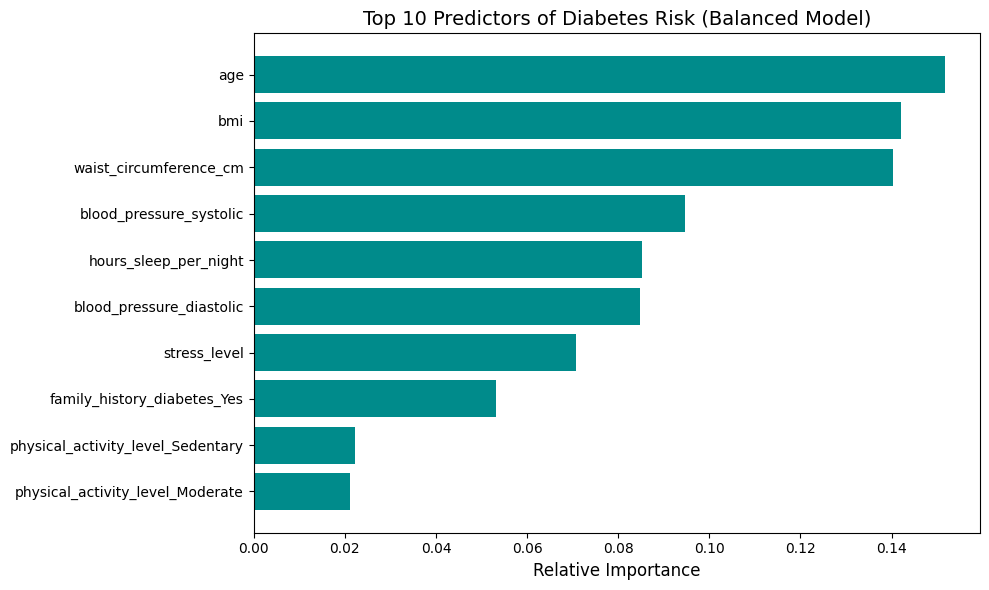

In [28]:
plt.figure(figsize=(10, 6))
plt.barh(feature_importance_df['Feature'][:10][::-1], feature_importance_df['Importance'][:10][::-1], color='darkcyan')
plt.title('Top 10 Predictors of Diabetes Risk (Balanced Model)', fontsize=14)
plt.xlabel('Relative Importance', fontsize=12)
plt.tight_layout()
plt.show()

In [29]:
import joblib
joblib.dump(rf_model, 'diabetes_risk_model_binary.pkl')
joblib.dump(scaler, 'diabetes_scaler_binary.pkl')
print("Model and scaler successfully exported for deployment!")

Model and scaler successfully exported for deployment!


In [32]:
import joblib

from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

     At_Risk       0.59      0.58      0.59      1181
         Low       0.73      0.74      0.74      1819

    accuracy                           0.68      3000
   macro avg       0.66      0.66      0.66      3000
weighted avg       0.68      0.68      0.68      3000



In [35]:
import joblib
idx = list(rf_model.classes_).index("At_Risk")
probs = rf_model.predict_proba(X_test)[:, idx]
y_bin = (y_test != "Low")   # counts anything that isn't Low as at risk

for t in [0.5, 0.4, 0.3, 0.25, 0.2]:
    pred = probs >= t
    tp = (pred & y_bin).sum()
    fn = (~pred & y_bin).sum()
    fp = (pred & ~y_bin).sum()
    print(f"cutoff {t}: recall {tp/(tp+fn):.2f}, false alarms {fp}")

cutoff 0.5: recall 0.58, false alarms 472
cutoff 0.4: recall 0.75, false alarms 772
cutoff 0.3: recall 0.87, false alarms 1113
cutoff 0.25: recall 0.91, false alarms 1307
cutoff 0.2: recall 0.95, false alarms 1474
